In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal, osr
import h5py
import scipy as sp
import skimage
#gdal.UseExceptions()

In [2]:
from scipy.fft import fft2, ifft2, fftshift
from scipy.interpolate import RectBivariateSpline
def fft_reshape(img, ref):
    a = fftshift(fft2(img))
    b = np.zeros(ref.shape, dtype=complex)
    #print(a.shape, b.shape)
    my, mx = (ref.shape[0]-img.shape[0])/2, (ref.shape[1]-img.shape[1])/2
    sy, sx = (my > 0), (mx > 0)
    #print(my, mx, sy, sx)
    a = a[int(-(1-sy)*my):int(img.shape[0]+(1-sy)*my), int(-(1-sx)*mx):int(img.shape[1]+(1-sx)*mx)]
    b[int(sy*my):int(img.shape[0]+(sy*2-1)*my), int(sx*mx):int(img.shape[1]+(sx*2-1)*mx)] = a
    b = ifft2(fftshift(b))
    return b

def interp_reshape(img, ref):
    x, y = np.linspace(0,ref.shape[0],img.shape[0]), np.linspace(0,ref.shape[1],img.shape[1])
    interp = RectBivariateSpline(x, y, img)
    x, y = np.meshgrid(np.arange(ref.shape[0]), np.arange(ref.shape[1]), indexing="ij")
    return interp.ev(x, y)
    
def crop(img, crop_factor):
    return img[:img.shape[0] // crop_factor, :img.shape[1] // crop_factor]

def coh(s1, s2, window_size=1): 
    wind = np.ones((window_size, window_size))/window_size**2
    edge = int(window_size / 2)
    val = sp.signal.convolve2d(np.abs(s1), wind, mode='same')
    val *= sp.signal.convolve2d(np.abs(s2), wind, mode='same')
    val = sp.signal.convolve2d(s1 * np.conj(s2), wind, mode='same') / val
    val[:edge] = val[-edge:] = np.nan#0
    val[:,:edge] = val[:,-edge:] = np.nan#0
    return val

def stackcoh(s1, s2, window_size=1):
    return np.stack([coh(s1[i], s2[i], window_size) for i in range(s1.shape[0])])

In [3]:
def import_datasets_h5(fn, str_filter=None, getDict=False):
    f = h5py.File(fn, 'r'); keys = list(f.keys()); nkeys = []; flag = True
    while (flag):
        keys = [[k for k in keys if hasattr(f[k], 'keys')], [k for k in keys if not hasattr(f[k], 'keys')]]
        nkeys = sum([[k1 + '/' + k2 for k2 in f[k1].keys()] for k1 in keys[0]], [])
        flag = len(keys[0]) > 0; keys = nkeys + keys[1]
    if (isinstance(str_filter, list)): keys = [el for el in keys if any(ft in el for ft in str_filter)]
    elif (isinstance(str_filter, str)): keys = [el for el in keys if str_filter in el]
    if (getDict): return {keys[i] : f[keys[i]] for i in range(len(keys))}
    return [f[keys[i]] for i in range(len(keys))]
    
fn_1 = "slc_bakerc/bakerc_16008_19059_012_190904_L090_CX_129_03.h5"
fn_2 = "slc_bakerc/bakerc_16008_19060_037_190905_L090_CX_129_03.h5"
    
# ://science/LSAR/SLC/metadata/geolocationGrid/heightAboveEllipsoid
s1_src = import_datasets_h5(fn_1, ["swaths/frequencyB/H", "swaths/frequencyB/V"])
s2_src = import_datasets_h5(fn_2, ["swaths/frequencyB/H", "swaths/frequencyB/V"])

gl1 = {el.name[el.name.rfind('/')+1:] : el for el in import_datasets_h5(fn_1, "metadata/geolocationGrid/")}
gl2 = {el.name[el.name.rfind('/')+1:] : el for el in import_datasets_h5(fn_2, "metadata/geolocationGrid/")}

ob1 = {el.name[el.name.rfind('/')+1:] : el for el in import_datasets_h5(fn_1, "metadata/orbit/")}
ob2 = {el.name[el.name.rfind('/')+1:] : el for el in import_datasets_h5(fn_2, "metadata/orbit/")}

In [4]:
#gl1.keys()
crop_factor = 4
ds_fill = -1e12

In [5]:
t1t, t1s, tmp, hae_r1 = np.array(gl1['zeroDopplerTime']), np.array(ob1['time']), np.array(ob1['position']), np.array(gl1['heightAboveEllipsoid'])
sp1 = np.array([np.interp(t1t, t1s, tmp[:,i]) for i in range(tmp.shape[1])])
shae_r1 = np.sum(sp1**2,axis=0)**0.5 # WGS84 src : https://topex.ucsd.edu/geodynamics/14gravity1_2.pdf
shae_r1 = (shae_r1**2 / (np.sum(sp1[(0,1)]**2, axis=0) / 6378137**2 + sp1[2]**2 / 6356752.3**2))**0.5

t2t, t2s, tmp, hae_r2 = np.array(gl2['zeroDopplerTime']), np.array(ob2['time']), np.array(ob2['position']), np.array(gl2['heightAboveEllipsoid'])
sp2 = np.array([np.interp(t2t, t2s, tmp[:,i]) for i in range(tmp.shape[1])])
shae_r2 = np.sum(sp2**2,axis=0)**0.5 # WGS84 src : https://topex.ucsd.edu/geodynamics/14gravity1_2.pdf
shae_r2 = (shae_r2**2 / (np.sum(sp2[(0,1)]**2, axis=0) / 6378137**2 + sp2[2]**2 / 6356752.3**2))**0.5

# interpolate geogrid dataset according to height bins (hgtbin, x, y) to (x, y) using hgt_ref match to interpolation of hgt_bins
def hgt_reshape(value, hgt_bins, hgt_ref, interp_sample_step=10):
    ia = [el.ravel() for el in np.meshgrid(hgt_bins, np.arange(value.shape[1]), np.arange(value.shape[2]), indexing='ij')]
    vval = value.copy(); vval[vval==ds_fill] = 0
    ia = np.stack(ia + [vval.ravel()], axis=1)
    ia = ia[np.arange(0, ia.shape[0], interp_sample_step)];
    interp = sp.interpolate.NearestNDInterpolator(ia[:, :-1], ia[:, -1])

    ib = [el.ravel() for el in np.meshgrid(np.arange(value.shape[1]), np.arange(value.shape[2]), indexing='ij')]
    ib = np.stack([np.fromiter(map(lambda x: hgt_ref[x], ib[0]), dtype=float)] + ib, axis=1)
    ib = interp(ib).reshape(value.shape[1:]); x,y,mask = np.arange(ib.shape[0]), np.arange(ib.shape[1]), ib==0
    ib = sp.interpolate.RectBivariateSpline(x, y, ib, s=1)(x, y); ib[mask] = 0
    return ib
    
def hgtfix_g1(value, interp_sample_step=10):
    return hgt_reshape(value, hae_r1, shae_r1, interp_sample_step)

def hgtfix_g2(value, interp_sample_step=10):
    return hgt_reshape(value, hae_r2, shae_r2, interp_sample_step)

def nancrop(im): #assumes symmetric pad, non-nan centreline
    a = [0 for i in range(len(im.shape))]
    for i in range(len(im.shape)):
        for k in range(im.shape[i]):
            chop = [im.shape[j]//2 for j in range(len(im.shape))]; chop[i] = k
            if ~np.isnan(im[tuple(chop)]): a[i] = k; break;
        a[i] = slice(a[i], im.shape[i] - a[i])
    return im[tuple(a)]

In [6]:
lk1 = np.array([hgtfix_g1(np.array(gl1['losUnitVectorX'])), hgtfix_g1(np.array(gl1['losUnitVectorY'])), hgtfix_g1(np.array(gl1['elevationAngle']))])
lk1[2] = np.sin(np.radians(lk1[2])) * (lk1[0]**2 + lk1[1]**2)**0.5; tmp = np.sum(lk1**2, axis=0)**0.5; tmp[tmp==0]=1; lk1 /= tmp
tp1 = np.array([hgtfix_g1(np.array(gl1['coordinateX'])), hgtfix_g1(np.array(gl1['coordinateY']))])

lk2 = np.array([hgtfix_g2(np.array(gl2['losUnitVectorX'])), hgtfix_g2(np.array(gl2['losUnitVectorY'])), hgtfix_g2(np.array(gl2['elevationAngle']))]);
lk2[2] = np.sin(np.radians(lk2[2])) * (lk2[0]**2 + lk2[1]**2)**0.5; tmp = np.sum(lk2**2, axis=0)**0.5; tmp[tmp==0]=1; lk2 /= tmp
tp2 = np.array([hgtfix_g2(np.array(gl2['coordinateX'])), hgtfix_g2(np.array(gl2['coordinateY']))])

## tp1 and tp2 are in the form (i, j, dimensions)
interps = [np.concatenate((tp2, lk2[i][np.newaxis])).reshape((tp2.shape[0]+1, tp2.shape[1]*tp2.shape[2])) for i in range(lk2.shape[0])]
interps = [sp.interpolate.LinearNDInterpolator(el[:2].T, el[2]) for el in interps]
lk2 = np.array([el(tp1.reshape((tp1.shape[0], tp1.shape[1]*tp1.shape[2])).T).reshape(lk1[0].shape) for el in interps])

lk2[lk2==0] = np.nan

incidence_angle_delta, tmp = np.sum(lk1*lk2, axis=0), (np.sum(lk1**2,axis=0)**0.5 * np.sum(lk2**2,axis=0)**0.5)
tmp[tmp==0] = 1; tmp[tmp>0] = 1; incidence_angle_delta[incidence_angle_delta==0] = 1;
incidence_angle_delta = np.arccos(incidence_angle_delta / tmp)
incidence_angle_delta[np.isnan(incidence_angle_delta)] = 0

incidence_angle = hgtfix_g1(np.array(gl1['incidenceAngle']));
incidence_angle[incidence_angle==ds_fill] = 0
incidence_angle = np.radians(incidence_angle)

x, y = np.arange(incidence_angle.shape[0]), np.arange(incidence_angle.shape[1])
interp = sp.interpolate.RectBivariateSpline(x, y, incidence_angle, s=8)
incidence_angle = interp(x, y)

#mask = incidence_angle==0
#incidence_angle[mask] = np.nan
#incidence_angle_delta[mask] = np.nan
#incidence_angle = nancrop(incidence_angle); incidence_angle[np.isnan(incidence_angle)]=0
#incidence_angle_delta = nancrop(incidence_angle_delta); incidence_angle_delta[np.isnan(incidence_angle_delta)]=0

In [7]:
#temp = tp1[0].copy()
#temp[temp==0] = np.nan
#plt.imshow(temp); plt.show()
#temp = np.array(gl1['coordinateX'])[0]
#temp[temp==ds_fill] = np.nan
#plt.imshow(temp)

In [8]:
def crop1d(d1arr): return d1arr[:d1arr.shape[0] // crop_factor]
s1dt = crop1d(np.array(import_datasets_h5(fn_1, "swaths/zeroDopplerTime")[0]))
s1sr = crop1d(np.array(import_datasets_h5(fn_1, "swaths/frequencyB/slantRange")[0]))
s2dt = crop1d(np.array(import_datasets_h5(fn_2, "swaths/zeroDopplerTime")[0]))
s2sr = crop1d(np.array(import_datasets_h5(fn_2, "swaths/frequencyB/slantRange")[0]))
g1sr, g2sr = np.array(gl1['slantRange']), np.array(gl2['slantRange'])

s1 = np.stack([crop(np.array(el),crop_factor) for el in s1_src], axis=0)
s2 = np.stack([crop(np.array(el),crop_factor) for el in s2_src], axis=0)

In [9]:
def scale_g2s(gval, g_dt, g_sr, s_dt, s_sr):
    a = sp.interpolate.RectBivariateSpline(g_dt, g_sr, gval, s=1)
    return a(s_dt, s_sr)

def scale_g2s1(gval): return scale_g2s(gval, t1t, g1sr, s1dt, s1sr)
def scale_g2s2(gval): return scale_g2s(gval, t2t, g2sr, s2dt, s2sr)
#plt.imshow(scale_g2s1(incidence_angle))
#print(tp1b.shape, t1t.shape, g1sr.shape)

In [10]:
tp1a, tp2a = tp1.copy(), tp2.copy()
tp1a = np.array((scale_g2s1(tp1a[0]), scale_g2s1(tp1a[1])))
tp2a = np.array((scale_g2s2(tp2a[0]), scale_g2s2(tp2a[1])))
tp1b = tp1a.reshape((tp1a.shape[0], np.prod(np.array(tp1a.shape[1:])))).T
tp2b = tp2a.reshape((tp2a.shape[0], np.prod(np.array(tp2a.shape[1:])))).T

In [11]:
#scraps
#tp1b[tp1b==0] = np.nan; tp2b[tp2b==0] = np.nan
#tp1b = np.array((np.abs(fft_reshape(nancrop(tp1b[0]), s1[0])), np.abs(fft_reshape(nancrop(tp1b[1]), s1[0]))))
#tp2b = np.array((np.abs(fft_reshape(nancrop(tp2b[0]), s2[0])), np.abs(fft_reshape(nancrop(tp2b[1]), s2[0]))))

#plt.imshow(tp1b[1], aspect=0.05)

#sample = (s2_interp[0][:,:2], s2_interp[0][:,0])
#epsilon = np.mean(np.abs(sample[0][1:] - sample[0][:-1]))*20
#s2_interp = ([sp.interpolate.RBFInterpolator(s2_interp[0][:,:2], s2_interp[0][:,i], neighbors=9, kernel='gaussian', epsilon=epsilon)
#              for i in range(2, s2_interp[0].shape[1])],
#             [sp.interpolate.RBFInterpolator(s2_interp[1][:,:2], s2_interp[1][:,i], neighbors=9, kernel='gaussian', epsilon=epsilon)
#              for i in range(2, s2_interp[1].shape[1])])
#s2o = np.array([el(tp1b) for el in s2_interp[0]]) + np.array([el(tp1b) for el in s2_interp[1]]) * 1j

#interp_sample_step = 10

def random_2dval(dim1, dim2, vmin, vmax):
    return (np.random.rand(dim1, dim2)*(vmax-vmin))+vmin
    
def random_2ducomplex(dim1, dim2, angmin, angmax):
    angymap = random_2dval(dim1, dim2, angmin, angmax)
    return np.sin(angymap) + np.cos(angymap) * 1j

    #k_z = (4*np.pi*incidence_angle_delta/(0.24*np.sin(incidence_angle)))
#k_z[np.isinf(k_z)] = np.nan
#a = 2 * 0.2 - 0.5 * (4*np.pi / 0.24)**2 * 0.2 * np.cos(incidence_angle) + 1j * k_z * np.cos(incidence_angle)
#b = (2*0.2 * np.exp(a) * 0.2 / np.cos(incidence_angle) - 1)
#c = (a * (np.exp(2 * 0.2 * 0.2 / np.cos(incidence_angle) - 1)))
#tempura = a / b

In [12]:
s2_interp = (np.concatenate((tp2b, s2.real.reshape((s2.shape[0], np.prod(np.array(s2.shape[1:])))).T), axis=1),
             np.concatenate((tp2b, s2.imag.reshape((s2.shape[0], np.prod(np.array(s2.shape[1:])))).T), axis=1))
topt = {"balanced_tree":False, "compact_nodes":False}
s2_interp = ([sp.interpolate.NearestNDInterpolator(s2_interp[0][:,:2], s2_interp[0][:,i], tree_options=topt) for i in range(2, s2_interp[0].shape[1])],
             [sp.interpolate.NearestNDInterpolator(s2_interp[1][:,:2], s2_interp[1][:,i], tree_options=topt) for i in range(2, s2_interp[1].shape[1])])
s2o = np.array([s2_interp[0][i](tp1b) + s2_interp[1][i](tp1b) * 1j for i in range(s2.shape[0])]).reshape(s1.shape)

In [13]:
flow = skimage.registration.optical_flow_ilk(np.abs(s2o[0]), np.abs(s1[0]), radius=30, num_warp=50)
#fig, ax = plt.subplots()
#im = ax.imshow(flow[0], aspect=0.05, cmap='viridis')
#plt.colorbar(im, ax=ax)
tmp = np.meshgrid(np.arange(s2o.shape[1]), np.arange(s2o.shape[2]), indexing='ij');
tmp = np.array([tmp[0]-flow[0], tmp[1]-flow[1]])
s2o = np.array([sp.ndimage.map_coordinates(s2o[i].real, tmp).astype(complex) +
                sp.ndimage.map_coordinates(s2o[i].real,tmp) * 1j for i in range(s2o.shape[0])])

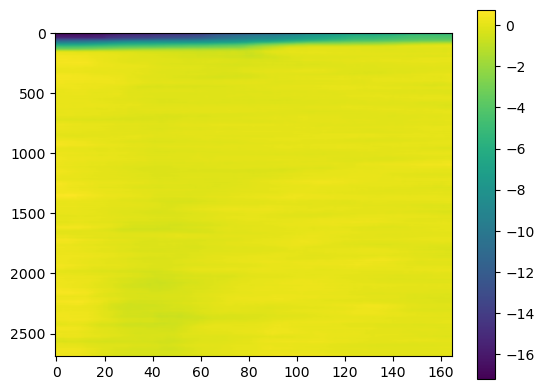

In [67]:
# VERIFICATION
flow2 = skimage.registration.optical_flow_ilk(np.abs(s2o[0]), np.abs(s1[0]), radius=20)
fig, ax = plt.subplots()
im = ax.imshow(flow2[0], aspect=0.05, cmap='viridis'); plt.colorbar(im, ax=ax)

In [15]:
#test_coh = coh((s1[0]), s2o[0], window_size=5)
#plt.imshow(np.abs(test_coh), aspect=0.05)

In [16]:
#plt.imshow((np.abs(np.abs(s1[0, 100:200, :50]).T))); plt.show()
#s2o = s2_interp[0][0](tp1b) + s2_interp[1][0](tp1b) * 1j
#a = np.abs(s2o.reshape(s1[0].shape)[100:200,:50])
#plt.imshow(np.abs(a).T)
#plt.imshow(scale_g2s1(incidence_angle), aspect=0.05)

# **The DF-RMoG Optimizer: Process Chain & Function**

### Purpose
The optimization process operates on products of a **single co-registered pair**. From this pair should be derived  the following products:
- **coherences** : a stack of temporal coherences calculated for each polarimetric basis, both real and derived.
- **incidence_angle**: a pixelwise map indicating the incidence angle.
- *base_offset* [DEPREC]* : a pixelwise map indicating the spatial separation of paired baselines.
- *slant_range* [DEPREC]* : a pixelwise map indicating the (averaged? May not survive far-field assumption..) slant range at time of capture.\
*: these should be calculated with incidence_angle to generate correct wavenumber (k_z) map, which should be a new input.
- **k_z** : a pixelwise map of derived interferometric vertical wavenumbers.

### Input Product Calculation
#### > **incidence_angle** - metadata properties
**UAVSAR:** \
Associated with UAVSAR products is an `.ann` file containing the necessary info, following the header `; from patchinfo file`. Also associated is an `.inc` file which contains an accurate pixelwise map of incidence angle, coregistered with full-size `.slc` data.

If using slant range and perpendicular baseline to calculate k_z, slant range must be calculated using backprojection via the `.hgt` file, which is matched with `.slc`. In the DF-RMoG paper, this is done via the **far-field assumption** (fig. 6, [src](https://www.mdpi.com/2072-4292/15/7/1877)) - this may not necessarily hold with UAVSAR, and so a slightly expanded approximation must be used.

The standard  method for k_z calculation is `k_z = 4*np.pi*(incidence_angle_difference) / (wavelength*np.sin(local_incidence_angle))`. Where the positions of both baselines can be approximated, this may be easier to model. *Incidence angle is taken from the interferometric master image.* (so far as i'm guessing)

In [17]:
class DFRMoG:
    def __init__(self, coherences, incidence_angle_map, incidence_angle_delta, wavelength=0.24,
                 init_learning_default=True, init_params_default=True):
        # -- physical parameters
        if (coherences[0].shape != incidence_angle_map.shape):
            raise ValueError("Mismatch in dimension between coherence[0] and incident angle map.")
        self.__coherences = coherences
        self.__incidence_angle_map = incidence_angle_map
        if ((not isinstance(incidence_angle_delta, float)) and (incidence_angle_map.shape != incidence_angle_delta.shape)):
            raise ValueError("Mismatch in dimension between incidence_angle_map and non-singular incidence_angle_delta.")
        self.__k_z = (4*np.pi*incidence_angle_delta/(wavelength*np.sin(incidence_angle_map)))
        self.__k_z[np.isinf(self.__k_z)] = np.nan
        self.__wavelength = wavelength
        self.linefit_coh()
        # -- learning parameters
        if(init_learning_default):
            self.init_learning()
        if(init_params_default):
            self.init_params()
        
    def init_learning(self, lr=0.001, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.m = None  # Initialize first moment vector
        self.v = None  # Initialize second moment vector
        self.t = 0.0     # Initialize timestep

    def init_params(self, extinction_coeff = 0.5, sq_variance = 0.5, h_v = 1.0, gvratios = None):
        param_extinction_coeff = np.full(self.__incidence_angle_map.shape, extinction_coeff)
        param_sq_variance = np.full(self.__incidence_angle_map.shape, sq_variance)
        param_h_v = np.full(self.__incidence_angle_map.shape, h_v)
        
        if (isinstance(gvratios, np.ndarray)):
            if (gvratios.shape == self.__coherences.shape): param_gvratios = gvratios
            else: raise ValueError("dimension mismatch between input gvratios and stored coherence.")
        elif (isinstance(gvratios, float)): param_gvratios = np.full(self.__coherences.shape, gvratios)
        else: param_gvratios = np.full(self.__coherences.shape, 0.5)
        self.params = [param_extinction_coeff, param_sq_variance, param_h_v]
        for gvr in param_gvratios:
            self.params.append(gvr)
        self.params = np.array(self.params)
    
    ## --  COHERENCE LINE FIT & GROUND POINT MATCH  -- ##
    ##     output: variables r_int, intersect_phase    ##
    def linefit_coh(self):
        bigcoh = np.argmax(np.abs(self.__coherences), axis=0)
        bigcoh = self.__coherences[bigcoh, np.arange(self.__coherences.shape[1])[:,None], np.arange(self.__coherences.shape[2])]
        self.__r_int = np.abs(bigcoh)

        # Reshape for vectorized regression
        coha_r = np.real(self.__coherences).reshape(self.__coherences.shape[0], -1).T  # shape: (N_pixels, T)
        coha_i = np.imag(self.__coherences).reshape(self.__coherences.shape[0], -1).T
        mask = ~np.isnan(coha_r).any(axis=1) & ~np.isnan(coha_i).any(axis=1)
        X, Y = np.stack([coha_r[mask], np.ones_like(coha_r[mask])], axis=2), coha_i[mask][..., None]  # shape: (N_valid, T, 2)
        # Least squares solution: beta = (X^T X)^-1 X^T y
        Xt = np.transpose(X, (0, 2, 1))  # (N_valid, 2, T)
        XtX, XtY = Xt @ X, Xt @ Y
        beta = np.linalg.solve(XtX, XtY).squeeze(-1)  # shape: (N_valid, 2)

        # Fill into coh_lins
        coh_lins = np.zeros((2, self.__r_int.shape[0], self.__r_int.shape[1]))
        flat_idx = np.where(mask)[0]
        for i, idx in enumerate(flat_idx):
            y, x = divmod(idx, self.__coherences.shape[2])
            coh_lins[:, y, x] = beta[i]
            
        a, b = coh_lins[0], coh_lins[1]
        c = 4*((a**2 + 1) * self.__r_int**2 - b**2)
        c[c < 0] = np.nan; c = np.sqrt(c) #nullifies invalid roots
        x1 = ((-2*a*b - c) / (2 * a**2 + 2)).astype(complex); x1 += (a*x1 + b)*1j
        x2 = ((-2*a*b + c) / (2 * a**2 + 2)).astype(complex); x2 += (a*x2 + b)*1j
        mask = np.abs(x1 - bigcoh) > np.abs(x2 - bigcoh)
        x1[mask] = x2[mask]
        self.__intersect_phase = np.arctan2(np.imag(x1),np.real(x1))
        return

    # takes in parameter images (2D, L x W) and ratio stack (3D, B x L x W) to form simulated coherence stack (3D)
    def coh_modelled(self, extinction_coeff, sq_variance, h_v, gvratios):
        if ((extinction_coeff.shape == sq_variance.shape == h_v.shape == gvratios[0].shape == self.__incidence_angle_map.shape == self.__k_z.shape) is False):
            #np.array([[[1,1], [1,1]], [[1,1], [1,1]]]) * np.array([[2,2],[2,2]]) - broadcast test for multiplication (it works)
            raise ValueError("input parameters (extinction_coeff, sq_variance, h_v, gvratios[i]) and stored parameters (incidence_angle_map[i], k_z[i]) contain dissimilar shapes.")
        a = 2 * extinction_coeff - 0.5 * (4*np.pi / self.__wavelength)**2 * sq_variance * np.cos(self.__incidence_angle_map) + 1j * self.__k_z * np.cos(self.__incidence_angle_map)
        veg_coh = (2*extinction_coeff * np.exp(a) * h_v / np.cos(self.__incidence_angle_map) - 1)
        tmp = (a * (np.exp(2 * extinction_coeff * h_v / np.cos(self.__incidence_angle_map)) - 1))
        tmp[(tmp==0)*(veg_coh==0)] = 1; veg_coh /= tmp
        tot_coh = np.exp(1j * self.__intersect_phase) * self.__r_int * (veg_coh + (gvratios/(gvratios + 1))*(1 - veg_coh))
        return tot_coh

    def error(self, params):
        return np.nanmean(np.abs(self.__coherences - self.coh_modelled(params[0], params[1], params[2], np.array(params[3:])))**2, axis=0)
        
    def finite_diff(self, epsilon=1e-4):
        if (not isinstance(epsilon, np.ndarray)):
            if(isinstance(epsilon, float)): epsilon = np.full(len(self.params), epsilon)
            else: raise ValueError("epsilon must be float or array.")
        elif (epsilon.shape != len(self.params)): raise ValueError("length of epsilon must either be one or equal to length of params.")
        grad = np.zeros_like(self.params)
        for i in range(len(self.params)):
            delta = np.zeros_like(self.params); delta[i] = epsilon[i]
            grad[i] = (self.error(self.params + delta) - self.error(self.params - delta)) / (2 * epsilon[i])
        return grad

    def converge(self, iterations=100, epsilon=1e-4, error_record=True, error_record_interval=10):
        if self.m is None or self.v is None: self.init_learning()
        error_history = np.zeros(int(iterations / error_record_interval))
        for i in range(iterations):
            grad = self.finite_diff(epsilon)
            if (error_record and i%error_record_interval==0):
                error = self.error(self.params)
                error_history[i // error_record_interval] = (np.nanmean(np.nanmean(np.nanmean(error, axis=0))))
                print("[##########"[:10*i//iterations+1]+"          ]"[10*i//iterations:]+str(i*100 / iterations)+"% - "+str(i)+"/"+str(iterations))
            self.params = self.update(self.params, grad)
        return (error_history) if error_record else None
    
    def update(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(param) for param in params]
            self.v = [np.zeros_like(param) for param in params]
        self.t += 1
        for i, param in enumerate(params):
            grad = grads[i]

            # Update biased first moment estimate
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * grad

            # Update biased second moment estimate
            self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * grad**2

            # Compute bias-corrected first moment estimate
            m_hat = self.m[i] / (1 - self.beta1**self.t)

            # Compute bias-corrected second moment estimate
            v_hat = self.v[i] / (1 - self.beta2**self.t)

            # Update parameters
            params[i] -= self.lr * m_hat / (np.sqrt(v_hat) + self.epsilon)

        return params
    
    #https://www.researchgate.net/publication/391785938_Joint-Pixel_Inversion_for_Ground_Phase_and_Forest_Height_Estimation_Using_Spaceborne_Polarimetric_SAR_Interferometry
    #(Huang et al., 2025) - use of ADMM method for lower-cost & less noisy inversion (not separate for every pixel)
    '''Input: Segmented covariance matrix T, matrix Ω, topographic phase ϕto po , maximum
    number of iterations Itermax, and the threshold Thr.
    2: Initialize the iterative parameters τand σwith random positive values.
    3: for iter <Itermax do
    4: Compute the coefﬁcient matrix F;
    5: Initialize αaccording to (29);
    6: Initialize ϕ0with a topographic phase, set z0=Fϕ0, and randomly initialize λ0;
    7: Estimate each ground phase ϕiusing the golden section search method (30);
    8: Update zand λin (32) and (27), respectively;
    9: if ∥ϕiter −ϕiter−1∥Q<Thr then
    10: break
    11: end if
    12: end for'''
    

In [69]:
incidence_angle_input = scale_g2s1(incidence_angle)
incidence_angle_delta_input = scale_g2s1(incidence_angle_delta)

tmp = np.concatenate((s1, s2o), axis=0)
watermask = np.sum(np.array([np.abs(tmp[i]) < np.nanmean(np.abs(tmp[i])) for i in range(tmp.shape[0])]), axis=0) > tmp.shape[0]*0.8
#plt.imshow(watermask, aspect=0.05)

full_s1 = np.concatenate((s1, np.array([s1[0]+s1[3], s1[1]+s1[2], s1[0]-s1[3]])), axis=0)
full_s2 = np.concatenate((s2o, np.array([s2o[0]+s2o[3], s2o[1]+s2o[2], s2o[0]-s2o[3]])), axis=0)

full_s1[:, watermask] = 1e-12
full_s2[:, watermask] = 1e-12

coh_stack = stackcoh(full_s1, full_s2, window_size=3)

In [66]:
#plt.imshow(np.abs(full_s1[4]) < np.nanmean(np.abs(full_s1[4]))/2, aspect=0.05)
#tmp = np.concatenate((full_s1, full_s2), axis=0)
#watermask = np.sum(np.array([np.abs(tmp[i]) < np.nanmean(np.abs(tmp[i])) for i in range(tmp.shape[0])]), axis=0) > tmp.shape[0]*0.8
#plt.imshow(watermask, aspect=0.05)

In [71]:
optimizer = DFRMoG(coh_stack, incidence_angle_input, incidence_angle_delta_input)

In [81]:
error_tracked = optimizer.converge(iterations=500, epsilon=0.02, error_record=True) # note - this can be called several times! Convenient.
#plt.plot(error_tracked[0])

/tmp/ipykernel_14303/3471056379.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.abs(self.__coherences - self.coh_modelled(params[0], params[1], params[2], np.array(params[3:])))**2, axis=0)
/tmp/ipykernel_14303/3471056379.py:112: RuntimeWarning: Mean of empty slice
  error_history[i // error_record_interval] = (np.nanmean(np.nanmean(np.nanmean(error, axis=0))))


[          ]0.0% - 0/500


/tmp/ipykernel_14303/3471056379.py:85: RuntimeWarning: invalid value encountered in exp
  veg_coh = (2*extinction_coeff * np.exp(a) * h_v / np.cos(self.__incidence_angle_map) - 1)
/tmp/ipykernel_14303/3471056379.py:87: RuntimeWarning: invalid value encountered in divide
  tmp[(tmp==0)*(veg_coh==0)] = 1; veg_coh /= tmp


[          ]2.0% - 10/500
[          ]4.0% - 20/500
[          ]6.0% - 30/500
[          ]8.0% - 40/500
[#         ]10.0% - 50/500
[#         ]12.0% - 60/500
[#         ]14.0% - 70/500
[#         ]16.0% - 80/500
[#         ]18.0% - 90/500
[##        ]20.0% - 100/500
[##        ]22.0% - 110/500
[##        ]24.0% - 120/500
[##        ]26.0% - 130/500
[##        ]28.0% - 140/500
[###       ]30.0% - 150/500
[###       ]32.0% - 160/500
[###       ]34.0% - 170/500
[###       ]36.0% - 180/500
[###       ]38.0% - 190/500
[####      ]40.0% - 200/500
[####      ]42.0% - 210/500
[####      ]44.0% - 220/500
[####      ]46.0% - 230/500
[####      ]48.0% - 240/500
[#####     ]50.0% - 250/500
[#####     ]52.0% - 260/500
[#####     ]54.0% - 270/500
[#####     ]56.0% - 280/500
[#####     ]58.0% - 290/500
[######    ]60.0% - 300/500
[######    ]62.0% - 310/500
[######    ]64.0% - 320/500
[######    ]66.0% - 330/500
[######    ]68.0% - 340/500
[#######   ]70.0% - 350/500
[#######   ]72.0% - 360/500
[####

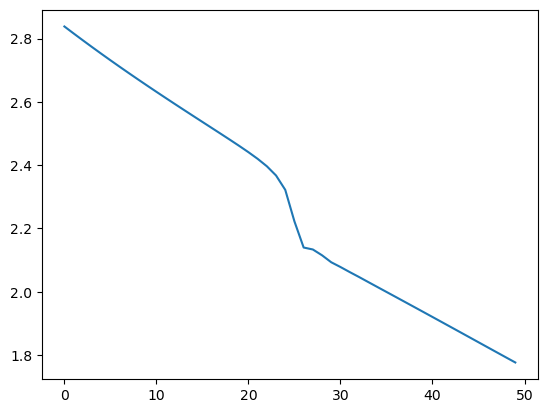

In [82]:
plt.plot(error_tracked)

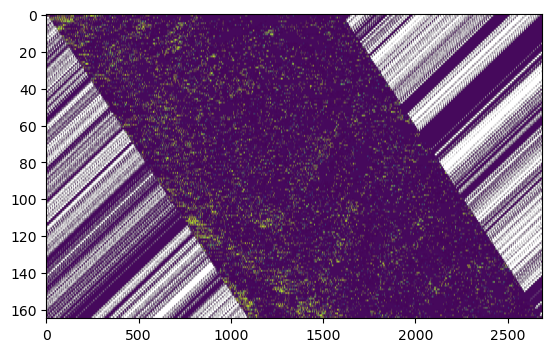

In [58]:
#plt.imshow(tp1[0])
#plt.plot(tp1a[0, 0, 0]); plt.show()
#plt.plot(tp1a[1, -1, -1])
#print(tp1a[0, 0, 0], tp1a[1, 0, 0])
#print(tp1a[0, -1, -1], tp1a[1, -1, -1])
#62.80, -114.54
#62.82, -114.66
tmp = optimizer.params[2].copy(); tmp[watermask] = 0.1;
imlook = tmp
lon = np.linspace(tp1a[0,0,0], tp1a[0,-1,-1], tp1a.shape[1])
lat = np.linspace(tp1a[1,0,0], tp1a[1,-1,-1], tp1a.shape[2])
lllook = np.stack([el.ravel() for el in np.meshgrid(lon, lat, indexing='ij')],axis=1)
interp = sp.interpolate.NearestNDInterpolator(tp1b, imlook.ravel())
imlook = interp(lllook).reshape((lon.shape[0], lat.shape[0]))
plt.imshow(np.log1p(imlook.T), aspect=10)

In [26]:
#print(lon[0],lon[-1],lon.shape[0], '  ', lat[0],lat[-1],lat.shape[0])
print(lat[0],',',lon[0]); print(lat[-1],',',lon[-2])

62.806678909401256 , -114.66718261371648
62.69067116079778 , -114.43804554374752


In [ ]:
# FOR COMPARISON - CREATE IMAGE OF RECTANGULAR & REGULAR GRID


In [460]:
#mask = np.mean(np.array([np.abs(s1[i])<np.mean(np.abs(s1[i])) for i in range(s1.shape[0])]), axis=0) < 1

In [502]:
#plt.imshow(np.log1p(np.log1p(mask * optimizer.params[0] / np.abs(s1[1]+s1[2]))), aspect=0.05); plt.show()
#plt.imshow(np.log1p(np.log1p(mask * optimizer.params[1] / np.abs(s1[1]+s1[2]))), aspect=0.05); plt.show()
#plt.imshow(np.log1p(np.log1p(mask * optimizer.params[2] / np.abs(s1[1]+s1[2]))), aspect=0.05); plt.show()
#plt.imshow(mask * , aspect=0.05)

#
#print(np.nanvar(optimizer.params[0]))
#print(np.nanvar(optimizer.params[1]))
#print(np.nanvar(optimizer.params[2]))

# - GVRatios
#print(np.nanvar(optimizer.params[3]))
#print(np.nanvar(optimizer.params[4]))
#print(np.nanvar(optimizer.params[5]))
#print(np.nanvar(optimizer.params[6]))
#plt.imshow(np.nanvar(optimizer.params[3:], axis=0), aspect=0.05)
#np.nanmean(np.nanvar(optimizer.params[3:], axis=0))

#print (np.nanmean(optimizer.params[2]))

In [19]:
#𝑓(𝜙′0,𝑟int,𝜎,Δ𝛿2,ℎ𝑣,𝑚1,𝑚2,𝑚3,𝑚4,𝑚5) = (𝛾1,𝛾2,𝛾3,𝛾4,𝛾5)
#wavelength = 0.23 #0.23m for ALOS-1 PALSAR L-band
#incidence_angle = np.radians(45) #NOTE - applicable for ALOS-1 PALSAR (check for other)
#k_z = 4 * np.pi * B / (wavelength * np.sin(incidence_angle) * range)
#note: phi_0 and r_int parameters can be taken without inversion (coherence line fit)
    #rmog_coh = np.zeros(m_stack.shape)
#METHOD TO USE - https://www.mdpi.com/2072-4292/15/7/1877 ("Dielectric Fluctuation and Random Motion over Ground Model (DF-RMoG): An Unsupervised Three-Stage Method of Forest Height Estimation Considering Dielectric Property Changes ")
#starting_parameters :
#  coeff_extinct = 0.2 (dB/m)
#  gm_variance = 3.6e-5
#  veg_h = 0
#  m_stack = [0, ...]       <-- this too????????
#  wavelength = 0.23 (m)
#  coh_gDF = 0.9*exp(-0.2i) <-- ?????? why??
#  loc_inc = 45 (deg)
#gvr = 0.5 #ground to volume ratio 


#sanAnDir = ["SanAnd/"+entry for entry in os.listdir("SanAnd") if entry[-3:]=='grd']
#sanAnGRD = [sanAnDir[0]+"/"+entry for entry in os.listdir(sanAnDir[0]) if entry[-3:]=='grd']
#sanAnAnn = [sanAnDir[0]+"/"+entry for entry in os.listdir(sanAnDir[0]) if entry[-3:]=='ann']
#dataset = gdal.Open(sanAnGRD[0], driver='uavsar')
#slc = SLC(hdf5file="SMAP_L1A_RADAR_01982_A_20150616T013144_R11850_001.h5") -- ISCE can't open SMAP files
#dataset = gdal.Open("SMAP_L1A_RADAR_01982_A_20150616T013144_R11850_001.h5") -- GDAL can't open SMAP files
#dataset.RasterCount